In [1]:

print("EconoCausal - Dynamic Pricing via Double Machine Learning")
print("Day 18: Business Interpretation of DML Results")
print("Project: Business Insights and Recommendations")


EconoCausal - Dynamic Pricing via Double Machine Learning
Day 18: Business Interpretation of DML Results
Project: Business Insights and Recommendations


In [2]:

from google.colab import files

uploaded = files.upload()


Saving Online Retail.xlsx to Online Retail.xlsx


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:

# Remove duplicate records
df_clean = df.drop_duplicates().copy()

# Convert columns to correct data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

# Keep valid transactions for this analysis
df_clean = df_clean.dropna(
    subset=["InvoiceDate", "UnitPrice", "Quantity"]
)

df_clean = df_clean[
    (df_clean["UnitPrice"] > 0) &
    (df_clean["Quantity"] > 0)
].copy()

# Create total sales column
df_clean["TotalSales"] = (
    df_clean["UnitPrice"] * df_clean["Quantity"]
)

print("Business analysis dataset prepared!")
print("Rows:", len(df_clean))

# Display basic business metrics
print("\nAverage Unit Price:", round(df_clean["UnitPrice"].mean(), 2))
print("Median Quantity:", round(df_clean["Quantity"].median(), 2))
print("Total Sales Value:", round(df_clean["TotalSales"].sum(), 2))


Business analysis dataset prepared!
Rows: 524878

Average Unit Price: 3.92
Median Quantity: 4.0
Total Sales Value: 10642110.8


In [5]:

# Analyze top 10 products by sales value
top_products = (
    df_clean.groupby("StockCode")
    .agg(
        TotalSales=("TotalSales", "sum"),
        AveragePrice=("UnitPrice", "mean"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("TotalSales", ascending=False)
    .head(10)
)

print("Top 10 Products by Total Sales:")
display(top_products)


Top 10 Products by Total Sales:


,TotalSales,AveragePrice,TotalQuantity
StockCode,,,
DOT,206248.77,292.137068,706
22423,174156.54,13.983936,13851
23843,168469.60,2.080000,80995
85123A,104462.75,3.117838,37641
47566,99445.23,5.797928,18283
85099B,94159.81,2.486197,48371
23166,81700.92,1.468480,78033
POST,78101.88,31.076581,3150
M,77750.27,234.489652,6984


Price-Quantity Correlation: -0.0038


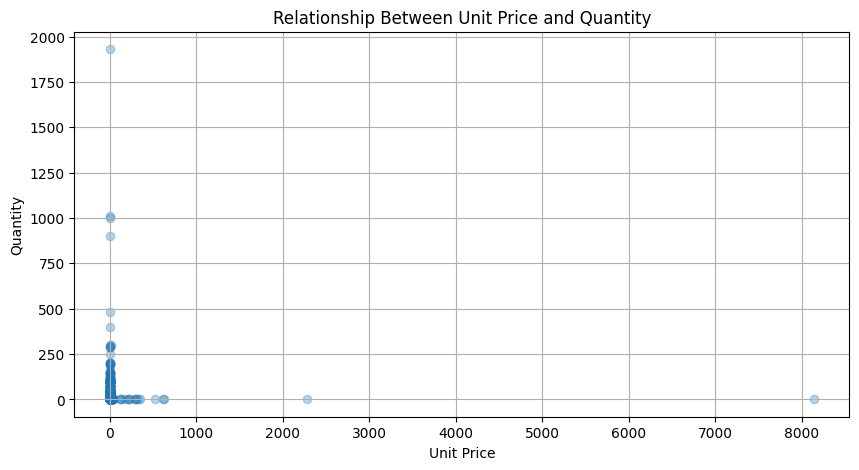

In [6]:

# Correlation between unit price and quantity
price_quantity_corr = df_clean[
    ["UnitPrice", "Quantity"]
].corr().iloc[0, 1]

print("Price-Quantity Correlation:", round(price_quantity_corr, 4))

# Scatter plot
sample_data = df_clean.sample(
    n=min(5000, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(10, 5))
plt.scatter(
    sample_data["UnitPrice"],
    sample_data["Quantity"],
    alpha=0.3
)
plt.title("Relationship Between Unit Price and Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.grid(True)
plt.show()


In [7]:

# Business Recommendations and Model Limitations

recommendations = [
    "Analyze product-level pricing before making price changes.",
    "Use historical sales patterns to support pricing decisions.",
    "Avoid assuming that correlation proves a causal relationship.",
    "Validate model findings before applying them in real business settings."
]

limitations = [
    "The dataset is observational, not a randomized experiment.",
    "Customer preferences and promotions may affect both price and quantity.",
    "Positive quantity and price filtering excludes returns and zero-price records.",
    "The estimated relationship may not generalize to every product or market."
]

print("BUSINESS RECOMMENDATIONS")
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

print("\nMODEL LIMITATIONS")
for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")


BUSINESS RECOMMENDATIONS
1. Analyze product-level pricing before making price changes.
2. Use historical sales patterns to support pricing decisions.
3. Avoid assuming that correlation proves a causal relationship.
4. Validate model findings before applying them in real business settings.

MODEL LIMITATIONS
1. The dataset is observational, not a randomized experiment.
2. Customer preferences and promotions may affect both price and quantity.
3. Positive quantity and price filtering excludes returns and zero-price records.
4. The estimated relationship may not generalize to every product or market.


In [8]:

# Save business analysis results
top_products.to_csv(
    "day18_top_products_business_analysis.csv"
)

print("Day 18 business analysis report saved!")


Day 18 business analysis report saved!


In [9]:

from google.colab import files

files.download("day18_top_products_business_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>